In [4]:
import pandas as pd
import numpy as np

In [52]:
sales = pd.read_csv('dataset/sales_train_evaluation.csv')
prices = pd.read_csv('dataset/sell_prices.csv')
calendar = pd.read_csv('dataset/calendar.csv')

In [6]:
sales.head()

,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,...,d_1932,d_1933,d_1934,d_1935,d_1936,d_1937,d_1938,d_1939,d_1940,d_1941
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,4,0,0,0,0,3,3,0,1
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,1,2,1,1,0,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,0,2,0,0,0,2,3,0,1
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,1,0,4,0,1,3,0,2,6
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,0,0,2,1,0,0,2,1,0


In [7]:
subset = sales[(sales['store_id'] == 'CA_1') & (sales['dept_id'] == 'FOODS_1')]
subset.shape

(216, 1947)

In [8]:
subset = sales[(sales['store_id'] == 'CA_1') & (sales['dept_id'] == 'HOUSEHOLD_1')]
subset.shape

(532, 1947)

In [9]:
day_cols = [c for c in subset.columns if c.startswith('d_')]

long = subset.melt(
    id_vars=['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id'],
    value_vars=day_cols,
    var_name='d',
    value_name='units_sold'
)

long.shape

(1032612, 8)

In [10]:
calendar_small = calendar[['d', 'date', 'wm_yr_wk', 'event_name_1']]
long = long.merge(calendar_small, on='d', how='left')
long.head()

,id,item_id,dept_id,cat_id,store_id,state_id,d,units_sold,date,wm_yr_wk,event_name_1
0,HOUSEHOLD_1_001_CA_1_evaluation,HOUSEHOLD_1_001,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,d_1,3,2011-01-29,11101,NaN
1,HOUSEHOLD_1_002_CA_1_evaluation,HOUSEHOLD_1_002,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,d_1,1,2011-01-29,11101,NaN
2,HOUSEHOLD_1_003_CA_1_evaluation,HOUSEHOLD_1_003,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,d_1,0,2011-01-29,11101,NaN
3,HOUSEHOLD_1_004_CA_1_evaluation,HOUSEHOLD_1_004,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,d_1,4,2011-01-29,11101,NaN
4,HOUSEHOLD_1_005_CA_1_evaluation,HOUSEHOLD_1_005,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,d_1,0,2011-01-29,11101,NaN


In [11]:
long = long.merge(prices, on=['store_id', 'item_id', 'wm_yr_wk'], how='left')
long['sell_price'].isna().sum()

np.int64(230699)

In [12]:
long = long.dropna(subset=['sell_price'])
long.shape

(801913, 12)

In [13]:
weekly = long.groupby(['item_id', 'wm_yr_wk']).agg(
    units_sold=('units_sold', 'sum'),
    sell_price=('sell_price', 'first'),
    date=('date', 'min'),
    has_event=('event_name_1', lambda x: x.notna().any())
).reset_index()

weekly.shape
weekly.head()

,item_id,wm_yr_wk,units_sold,sell_price,date,has_event
0,HOUSEHOLD_1_001,11101,3,6.32,2011-01-29,False
1,HOUSEHOLD_1_001,11102,4,6.32,2011-02-05,True
2,HOUSEHOLD_1_001,11103,1,6.32,2011-02-12,True
3,HOUSEHOLD_1_001,11104,3,6.32,2011-02-19,True
4,HOUSEHOLD_1_001,11105,2,6.32,2011-02-26,False


In [14]:
weekly.shape

(114939, 6)

In [15]:
prices_per_item = weekly.groupby('item_id')['sell_price'].nunique()

prices_per_item.describe()
(prices_per_item > 1).sum()

np.int64(367)

In [16]:
items_with_change = prices_per_item[prices_per_item > 1].index
weekly = weekly[weekly['item_id'].isin(items_with_change)]
weekly.shape

(84464, 6)

In [17]:
base_price = weekly.groupby('item_id')['sell_price'].transform('max')
weekly['discount'] = (base_price - weekly['sell_price']) / base_price

weekly['discount'].describe()

count    84464.000000
mean         0.037049
std          0.058791
min          0.000000
25%          0.000000
50%          0.006036
75%          0.061466
max          0.996212
Name: discount, dtype: float64

In [18]:
print((weekly['discount'] > 0.2).sum())
print((weekly['discount'] > 0.5).sum())
weekly[weekly['discount'] > 0.5].head(10)

1243
175


,item_id,wm_yr_wk,units_sold,sell_price,date,has_event,discount
16856,HOUSEHOLD_1_077,11450,1,1.00,2015-01-10,False,0.856734
23875,HOUSEHOLD_1_109,11438,10,1.00,2014-10-18,False,0.748111
25116,HOUSEHOLD_1_116,11449,1,1.00,2015-01-03,True,0.663300
35927,HOUSEHOLD_1_165,11526,5,2.00,2015-07-25,False,0.888703
40363,HOUSEHOLD_1_183,11448,1,1.88,2014-12-27,True,0.614754
40364,HOUSEHOLD_1_183,11449,0,1.88,2015-01-03,True,0.614754
40365,HOUSEHOLD_1_183,11450,0,1.88,2015-01-10,False,0.614754
40366,HOUSEHOLD_1_183,11451,0,1.88,2015-01-17,True,0.614754
40367,HOUSEHOLD_1_183,11452,0,1.88,2015-01-24,False,0.614754
40368,HOUSEHOLD_1_183,11501,0,1.88,2015-01-31,True,0.614754


In [19]:
weekly = weekly[weekly['discount'] <= 0.5]
weekly.shape

(84289, 7)

In [20]:
weekly['date'] = pd.to_datetime(weekly['date'])
weekly['month'] = weekly['date'].dt.month
weekly['week_of_year'] = weekly['date'].dt.isocalendar().week.astype(int)
weekly['base_price'] = weekly.groupby('item_id')['sell_price'].transform('max')

weekly = weekly.sort_values(['date', 'item_id']).reset_index(drop=True)
weekly.head()

,item_id,wm_yr_wk,units_sold,sell_price,date,has_event,discount,month,week_of_year,base_price
0,HOUSEHOLD_1_001,11101,3,6.32,2011-01-29,False,0.093257,1,4,6.97
1,HOUSEHOLD_1_002,11101,9,6.32,2011-01-29,False,0.093257,1,4,6.97
2,HOUSEHOLD_1_004,11101,27,1.98,2011-01-29,False,0.164557,1,4,2.37
3,HOUSEHOLD_1_005,11101,11,10.72,2011-01-29,False,0.000000,1,4,10.72
4,HOUSEHOLD_1_015,11101,1,4.74,2011-01-29,False,0.193878,1,4,5.88


In [21]:
weekly['has_event'] = weekly['has_event'].astype(int)

features = ['discount', 'base_price', 'month', 'week_of_year', 'has_event']

cutoff = weekly['date'].max() - pd.Timedelta(weeks=26)
train = weekly[weekly['date'] <= cutoff]
test = weekly[weekly['date'] > cutoff]

print(train.shape, test.shape)

(74778, 10) (9511, 10)


In [22]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

lr = LinearRegression()
lr.fit(train[features], train['units_sold'])
pred = lr.predict(test[features])

print('MAE:', mean_absolute_error(test['units_sold'], pred))
print('R2:', r2_score(test['units_sold'], pred))
print(dict(zip(features, lr.coef_)))

MAE: 8.713081260542241
R2: 0.06762153287083184
{'discount': np.float64(8.642885491431304), 'base_price': np.float64(-1.0013696005313613), 'month': np.float64(-0.2581461811950997), 'week_of_year': np.float64(0.06157827722964311), 'has_event': np.float64(-0.234180501470142)}


In [23]:
weekly = weekly.sort_values(['item_id', 'date']).reset_index(drop=True)

weekly['lag_1'] = weekly.groupby('item_id')['units_sold'].shift(1)
weekly['roll_4'] = weekly.groupby('item_id')['units_sold'].transform(
    lambda x: x.shift(1).rolling(4).mean()
)

weekly = weekly.dropna(subset=['lag_1', 'roll_4'])

features = ['discount', 'base_price', 'month', 'week_of_year', 'has_event', 'lag_1', 'roll_4']

cutoff = weekly['date'].max() - pd.Timedelta(weeks=26)
train = weekly[weekly['date'] <= cutoff]
test = weekly[weekly['date'] > cutoff]

lr = LinearRegression()
lr.fit(train[features], train['units_sold'])
pred = lr.predict(test[features])

print(train.shape, test.shape)
print('Average weekly units in test:', test['units_sold'].mean())
print('MAE:', mean_absolute_error(test['units_sold'], pred))
print('R2:', r2_score(test['units_sold'], pred))

(73313, 12) (9511, 12)
Average weekly units in test: 10.83419198822416
MAE: 3.6808490070277378
R2: 0.8336008513135338


In [24]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [25]:
from xgboost import XGBRegressor

xgb = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, random_state=42)
xgb.fit(train[features], train['units_sold'])
pred_xgb = xgb.predict(test[features])

print('XGB MAE:', mean_absolute_error(test['units_sold'], pred_xgb))
print('XGB R2:', r2_score(test['units_sold'], pred_xgb))
print(dict(zip(features, xgb.feature_importances_.round(3))))

XGB MAE: 3.820998430252075
XGB R2: 0.7802181243896484
{'discount': np.float32(0.015), 'base_price': np.float32(0.019), 'month': np.float32(0.014), 'week_of_year': np.float32(0.024), 'has_event': np.float32(0.019), 'lag_1': np.float32(0.13), 'roll_4': np.float32(0.779)}


In [26]:
weekly['prev_discount'] = weekly.groupby('item_id')['discount'].shift(1)
weekly['discount_change'] = weekly['discount'] - weekly['prev_discount']
weekly = weekly.dropna(subset=['prev_discount'])

features2 = features + ['prev_discount', 'discount_change']

cutoff = weekly['date'].max() - pd.Timedelta(weeks=26)
train = weekly[weekly['date'] <= cutoff]
test = weekly[weekly['date'] > cutoff]

print('Avg units - train:', train['units_sold'].mean(), ' test:', test['units_sold'].mean())

xgb2 = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, random_state=42)
xgb2.fit(train[features2], np.log1p(train['units_sold']))
pred2 = np.expm1(xgb2.predict(test[features2]))

print('XGB2 MAE:', mean_absolute_error(test['units_sold'], pred2))
print('XGB2 R2:', r2_score(test['units_sold'], pred2))
print(pd.Series(xgb2.feature_importances_, index=features2).sort_values(ascending=False).round(3))

Avg units - train: 9.897185627921642  test: 10.83419198822416
XGB2 MAE: 3.753650426864624
XGB2 R2: 0.7959380149841309
roll_4             0.652
lag_1              0.307
discount_change    0.023
base_price         0.005
week_of_year       0.003
discount           0.003
prev_discount      0.003
month              0.002
has_event          0.002
dtype: float32


In [27]:
baseline_features = ['base_price', 'month', 'week_of_year', 'has_event', 'lag_1', 'roll_4']

baseline = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, random_state=42)
baseline.fit(train[baseline_features], np.log1p(train['units_sold']))

train_baseline_pred = np.expm1(baseline.predict(train[baseline_features]))
test_baseline_pred = np.expm1(baseline.predict(test[baseline_features]))

train_residual = train['units_sold'] - train_baseline_pred
test_residual = test['units_sold'] - test_baseline_pred

print('Baseline MAE:', mean_absolute_error(test['units_sold'], test_baseline_pred))
print('Baseline R2:', r2_score(test['units_sold'], test_baseline_pred))

import numpy as np
corr = np.corrcoef(train['discount'], train_residual)[0, 1]
print('Correlation between discount and residual:', corr)

Baseline MAE: 3.7513585090637207
Baseline R2: 0.794623076915741
Correlation between discount and residual: 0.012767002520354032


In [28]:
latest = weekly.sort_values('date').groupby('item_id').tail(1).copy()

latest['Q_base'] = np.expm1(baseline.predict(latest[baseline_features]))
latest['P_base'] = latest['sell_price']

latest[['item_id', 'P_base', 'Q_base']].head(10)

,item_id,P_base,Q_base
84010,HOUSEHOLD_1_540,1.88,16.358463
35856,HOUSEHOLD_1_222,9.97,27.471224
35298,HOUSEHOLD_1_219,6.48,2.530012
18937,HOUSEHOLD_1_117,7.97,3.053870
36304,HOUSEHOLD_1_225,1.88,17.220310
36683,HOUSEHOLD_1_228,9.47,2.995209
35584,HOUSEHOLD_1_221,12.57,3.026332
18659,HOUSEHOLD_1_116,2.97,2.102141
35466,HOUSEHOLD_1_220,1.83,5.465680
36134,HOUSEHOLD_1_224,7.97,2.719095


In [29]:
def generate_price_candidates(p_base, q_base, elasticity, discount_range=np.arange(-0.3, 0.31, 0.05)):
    results = []
    for d in discount_range:
        p_new = p_base * (1 - d)
        q_new = q_base * (p_new / p_base) ** elasticity
        results.append({'discount': d, 'price': p_new, 'predicted_demand': q_new})
    return pd.DataFrame(results)

In [30]:
row = latest.iloc[0]
candidates = generate_price_candidates(row['P_base'], row['Q_base'], elasticity=-1.0)
candidates

,discount,price,predicted_demand
0,-3.000000e-01,2.444,12.583433
1,-2.500000e-01,2.350,13.086771
2,-2.000000e-01,2.256,13.632053
3,-1.500000e-01,2.162,14.224751
4,-1.000000e-01,2.068,14.871330
5,-5.000000e-02,1.974,15.579489
6,-5.551115e-17,1.880,16.358463
7,5.000000e-02,1.786,17.219435
8,1.000000e-01,1.692,18.176070
9,1.500000e-01,1.598,19.245251


In [31]:
def generate_price_candidates(p_base, q_base, elasticity, discount_range=np.arange(-0.3, 0.31, 0.05)):
    results = []
    for d in discount_range:
        p_new = p_base * (1 - d)
        q_new = q_base * (p_new / p_base) ** elasticity
        revenue = p_new * q_new
        results.append({'discount': d, 'price': p_new, 'predicted_demand': q_new, 'revenue': revenue})
    return pd.DataFrame(results)

candidates = generate_price_candidates(row['P_base'], row['Q_base'], elasticity=-1.0)
best_row = candidates.loc[candidates['revenue'].idxmax()]
print(best_row)

discount            -0.250000
price                2.350000
predicted_demand    13.086771
revenue             30.753911
Name: 1, dtype: float64


In [32]:
for e in [-0.5, -1.0, -1.5, -2.0]:
    candidates = generate_price_candidates(row['P_base'], row['Q_base'], elasticity=e)
    best = candidates.loc[candidates['revenue'].idxmax()]
    print(f"E={e}: best discount={best['discount']:.2f}, price={best['price']:.2f}, revenue={best['revenue']:.2f}")

E=-0.5: best discount=-0.30, price=2.44, revenue=35.06
E=-1.0: best discount=-0.25, price=2.35, revenue=30.75
E=-1.5: best discount=0.30, price=1.32, revenue=36.76
E=-2.0: best discount=0.30, price=1.32, revenue=43.93


In [33]:
def apply_inventory_constraint(candidates, stock):
    candidates = candidates.copy()
    candidates['sellable'] = np.minimum(candidates['predicted_demand'], stock)
    candidates['constrained_revenue'] = candidates['price'] * candidates['sellable']
    return candidates

stock = 10
constrained = apply_inventory_constraint(candidates, stock)
best_constrained = constrained.loc[constrained['constrained_revenue'].idxmax()]
print(best_constrained)

discount               -0.300000
price                   2.444000
predicted_demand        9.679564
revenue                23.656855
sellable                9.679564
constrained_revenue    23.656855
Name: 0, dtype: float64


In [34]:
stock_high = 50
constrained_high = apply_inventory_constraint(candidates, stock_high)
best_high = constrained_high.loc[constrained_high['constrained_revenue'].idxmax()]
print(best_high)

discount                0.300000
price                   1.316000
predicted_demand       33.384619
revenue                43.934159
sellable               33.384619
constrained_revenue    43.934159
Name: 12, dtype: float64


In [35]:
def recommend_price(item_id, elasticity, stock, discount_range=np.arange(-0.3, 0.31, 0.05)):
    row = latest[latest['item_id'] == item_id].iloc[0]
    candidates = generate_price_candidates(row['P_base'], row['Q_base'], elasticity, discount_range)
    constrained = apply_inventory_constraint(candidates, stock)
    best = constrained.loc[constrained['constrained_revenue'].idxmax()]
    return best

In [36]:
print(recommend_price('HOUSEHOLD_1_540', elasticity=-1.5, stock=5))
print(recommend_price('HOUSEHOLD_1_222', elasticity=-1.5, stock=100))

discount               -0.300000
price                   2.444000
predicted_demand       11.036401
revenue                26.972964
sellable                5.000000
constrained_revenue    12.220000
Name: 0, dtype: float64
discount                 0.300000
price                    6.979000
predicted_demand        46.906275
revenue                327.358895
sellable                46.906275
constrained_revenue    327.358895
Name: 12, dtype: float64


In [37]:
wide_range = np.arange(-0.6, 0.31, 0.05)
print(recommend_price('HOUSEHOLD_1_540', elasticity=-1.5, stock=5, discount_range=wide_range))

discount               -0.600000
price                   3.008000
predicted_demand        8.082813
revenue                24.313101
sellable                5.000000
constrained_revenue    15.040000
Name: 0, dtype: float64


In [38]:
def recommend_price(item_id, elasticity, stock, max_increase=0.2, max_discount=0.3):
    row = latest[latest['item_id'] == item_id].iloc[0]
    discount_range = np.arange(-max_increase, max_discount + 0.01, 0.05)
    candidates = generate_price_candidates(row['P_base'], row['Q_base'], elasticity, discount_range)
    constrained = apply_inventory_constraint(candidates, stock)
    best = constrained.loc[constrained['constrained_revenue'].idxmax()]
    return best

print(recommend_price('HOUSEHOLD_1_540', elasticity=-1.5, stock=5))

discount               -0.200000
price                   2.256000
predicted_demand       12.444305
revenue                28.074351
sellable                5.000000
constrained_revenue    11.280000
Name: 0, dtype: float64


In [39]:
SCENARIOS = {'Conservative': -0.5, 'Moderate': -1.0, 'Aggressive': -1.5}

def recommend_price(item_id, scenario, stock, max_increase=0.2, max_discount=0.3):
    elasticity = SCENARIOS[scenario]
    row = latest[latest['item_id'] == item_id].iloc[0]
    discount_range = np.arange(-max_increase, max_discount + 0.01, 0.05)
    candidates = generate_price_candidates(row['P_base'], row['Q_base'], elasticity, discount_range)
    constrained = apply_inventory_constraint(candidates, stock)
    best = constrained.loc[constrained['constrained_revenue'].idxmax()]
    return best

for scenario in SCENARIOS:
    result = recommend_price('HOUSEHOLD_1_540', scenario, stock=5)
    print(scenario, '->', result['discount'], result['price'], result['constrained_revenue'])

Conservative -> -0.2 2.256 11.28
Moderate -> -0.2 2.256 11.28
Aggressive -> -0.2 2.256 11.28


In [40]:
edge_cases = [
    ('HOUSEHOLD_1_540', 'Moderate', 0),     # zero stock
    ('HOUSEHOLD_1_540', 'Moderate', 1),     # almost no stock
    ('HOUSEHOLD_1_540', 'Moderate', 10000), # effectively unlimited stock
]

for item_id, scenario, stock in edge_cases:
    print(item_id, scenario, stock, '->')
    print(recommend_price(item_id, scenario, stock))
    print()

HOUSEHOLD_1_540 Moderate 0 ->
discount               -0.200000
price                   2.256000
predicted_demand       13.632053
revenue                30.753911
sellable                0.000000
constrained_revenue     0.000000
Name: 0, dtype: float64

HOUSEHOLD_1_540 Moderate 1 ->
discount               -0.200000
price                   2.256000
predicted_demand       13.632053
revenue                30.753911
sellable                1.000000
constrained_revenue     2.256000
Name: 0, dtype: float64

HOUSEHOLD_1_540 Moderate 10000 ->
discount               -0.100000
price                   2.068000
predicted_demand       14.871330
revenue                30.753911
sellable               14.871330
constrained_revenue    30.753911
Name: 2, dtype: float64



In [41]:
def recommend_price(item_id, scenario, stock, max_increase=0.2, max_discount=0.3):
    if stock <= 0:
        return {'status': 'out_of_stock', 'item_id': item_id}
    
    elasticity = SCENARIOS[scenario]
    row = latest[latest['item_id'] == item_id].iloc[0]
    discount_range = np.arange(-max_increase, max_discount + 0.01, 0.05)
    candidates = generate_price_candidates(row['P_base'], row['Q_base'], elasticity, discount_range)
    constrained = apply_inventory_constraint(candidates, stock)
    best = constrained.loc[constrained['constrained_revenue'].idxmax()]
    return {'status': 'ok', **best.to_dict()}

print(recommend_price('HOUSEHOLD_1_540', 'Moderate', 0))
print(recommend_price('HOUSEHOLD_1_540', 'Moderate', 5))

{'status': 'out_of_stock', 'item_id': 'HOUSEHOLD_1_540'}
{'status': 'ok', 'discount': -0.2, 'price': 2.256, 'predicted_demand': 13.632052739461264, 'revenue': 30.753910980224607, 'sellable': 5.0, 'constrained_revenue': 11.28}


In [42]:
print(recommend_price('HOUSEHOLD_1_540', 'Conservative', 10000))
print(recommend_price('HOUSEHOLD_1_540', 'Aggressive', 10000))

{'status': 'ok', 'discount': -0.2, 'price': 2.256, 'predicted_demand': 14.933165581006058, 'revenue': 33.689221550749664, 'sellable': 14.933165581006058, 'constrained_revenue': 33.689221550749664}
{'status': 'ok', 'discount': 0.2999999999999999, 'price': 1.3160000000000003, 'predicted_demand': 27.93157617970181, 'revenue': 36.75795425248759, 'sellable': 27.93157617970181, 'constrained_revenue': 36.75795425248759}


In [43]:
print(recommend_price('HOUSEHOLD_1_222', 'Conservative', stock=20))
print(recommend_price('HOUSEHOLD_1_222', 'Moderate', stock=20))
print(recommend_price('HOUSEHOLD_1_222', 'Aggressive', stock=20))

{'status': 'ok', 'discount': -0.2, 'price': 11.964, 'predicted_demand': 25.077681624348337, 'revenue': 300.02938295370353, 'sellable': 20.0, 'constrained_revenue': 239.28}
{'status': 'ok', 'discount': -0.2, 'price': 11.964, 'predicted_demand': 22.892686525980633, 'revenue': 273.8881015968323, 'sellable': 20.0, 'constrained_revenue': 239.28}
{'status': 'ok', 'discount': -0.2, 'price': 11.964, 'predicted_demand': 20.89806802029028, 'revenue': 250.02448579475293, 'sellable': 20.0, 'constrained_revenue': 239.28}


In [44]:
for scenario in SCENARIOS:
    r = recommend_price('HOUSEHOLD_1_222', scenario, stock=15)
    print(scenario, '->', r['discount'], r['price'], r['constrained_revenue'])

Conservative -> -0.2 11.964 179.46
Moderate -> -0.2 11.964 179.46
Aggressive -> -0.2 11.964 179.46


In [45]:
for scenario in SCENARIOS:
    r = recommend_price('HOUSEHOLD_1_222', scenario, stock=30)
    print(scenario, '->', r['discount'], r['price'], r['constrained_revenue'])

Conservative -> -0.2 11.964 300.02938295370353
Moderate -> -0.2 11.964 273.8881015968323
Aggressive -> 0.04999999999999993 9.4715 281.00326313204926


In [46]:
validation_results = []

for item_id in latest['item_id'].unique():
    for scenario in SCENARIOS:
        r = recommend_price(item_id, scenario, stock=15)
        if r['status'] == 'ok':
            validation_results.append({
                'item_id': item_id,
                'scenario': scenario,
                'P_base': r.get('price'),
                'discount': r['discount'],
                'predicted_demand': r['predicted_demand'],
                'sellable': r['sellable'],
                'constrained_revenue': r['constrained_revenue']
            })

validation_df = pd.DataFrame(validation_results)
validation_df.shape

(1098, 7)

In [47]:
summary = validation_df.groupby('scenario').agg(
    avg_discount=('discount', 'mean'),
    pct_pinned_low=('discount', lambda x: (x <= -0.19).mean()),
    pct_pinned_high=('discount', lambda x: (x >= 0.29).mean()),
    avg_revenue=('constrained_revenue', 'mean')
).round(3)

summary

,avg_discount,pct_pinned_low,pct_pinned_high,avg_revenue
scenario,,,,
Aggressive,0.203,0.112,0.656,35.220
Conservative,-0.200,1.000,0.000,34.140
Moderate,-0.142,0.546,0.003,31.632


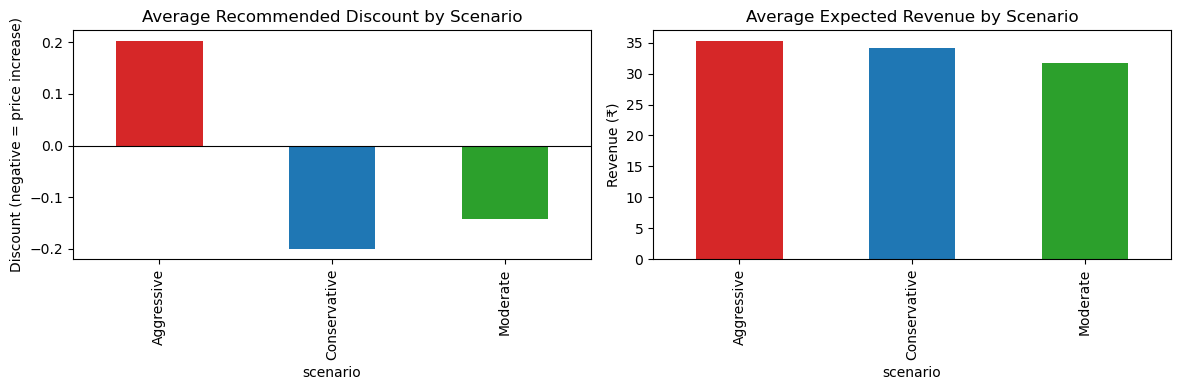

In [48]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

summary['avg_discount'].plot(kind='bar', ax=axes[0], color=['#d62728', '#1f77b4', '#2ca02c'])
axes[0].set_title('Average Recommended Discount by Scenario')
axes[0].set_ylabel('Discount (negative = price increase)')
axes[0].axhline(0, color='black', linewidth=0.8)

summary['avg_revenue'].plot(kind='bar', ax=axes[1], color=['#d62728', '#1f77b4', '#2ca02c'])
axes[1].set_title('Average Expected Revenue by Scenario')
axes[1].set_ylabel('Revenue (₹)')

plt.tight_layout()
plt.savefig('scenario_comparison.png', dpi=150)
plt.show()

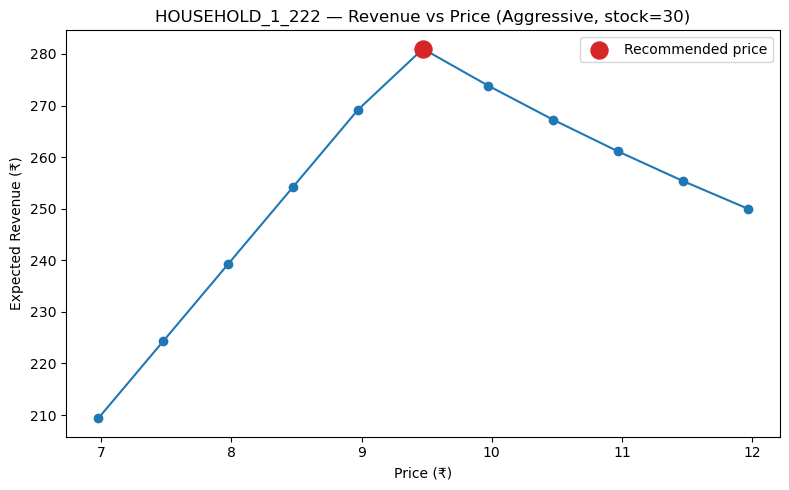

In [49]:
def plot_price_curve(item_id, scenario, stock, max_increase=0.2, max_discount=0.3):
    elasticity = SCENARIOS[scenario]
    row = latest[latest['item_id'] == item_id].iloc[0]
    discount_range = np.arange(-max_increase, max_discount + 0.01, 0.05)
    candidates = generate_price_candidates(row['P_base'], row['Q_base'], elasticity, discount_range)
    constrained = apply_inventory_constraint(candidates, stock)
    
    best_idx = constrained['constrained_revenue'].idxmax()
    
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(constrained['price'], constrained['constrained_revenue'], marker='o', color='#1f77b4')
    ax.scatter(constrained.loc[best_idx, 'price'], constrained.loc[best_idx, 'constrained_revenue'],
               color='#d62728', s=150, zorder=5, label='Recommended price')
    ax.set_xlabel('Price (₹)')
    ax.set_ylabel('Expected Revenue (₹)')
    ax.set_title(f'{item_id} — Revenue vs Price ({scenario}, stock={stock})')
    ax.legend()
    plt.tight_layout()
    return fig

fig = plot_price_curve('HOUSEHOLD_1_222', 'Aggressive', stock=30)
plt.show()